In [ ]:
!pip install -U tensorflow opencv-python matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 110.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 131.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 35.4 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
  Attempting uninstall: tensorflow
    Found existing installation: tensorflow 2.20.0
    Uninstalling tensorflow-2.20.0:


In [ ]:
import os
import tensorflow as tf

In [ ]:
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

In [ ]:
tf. config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
import cv2
from PIL import Image

In [ ]:
data_dir = 'data'

In [ ]:
os.listdir(data_dir)

['AI', 'AI ai ', '.ipynb_checkpoints']

In [ ]:
image_exts = ["jpeg", "jpg", "bmp", "png"]

In [ ]:
for image_class in os.listdir(data_dir):
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        if os.path.isdir(image_path): # Skip directories
            continue
        try:
            # Try to open the image with Pillow to get its format
            with Image.open(image_path) as img_pil:
                # Get the format and convert to lowercase for consistent comparison
                img_format = img_pil.format.lower()

            # Check if the image format is in the allowed extensions list
            if img_format not in image_exts:
                print('Image not in ext list ({}): {}'.format(img_format, image_path))
                os.remove(image_path)
        except (IOError, OSError) as e:
            # Handle cases where Pillow cannot open the file (e.g., corrupt or not an image)
            print('Issue with image (corrupt or invalid format): {} - {}'.format(image_path, e))
            # Optionally remove the problematic file, depending on desired behavior
            os.remove(image_path)
        except Exception as e:
            # Catch any other unexpected errors
            print('Unexpected issue with image {}: {}'.format(image_path, e))
            # os.remove(image_path) # Uncomment to remove on any exception

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
data = tf.keras.utils.image_dataset_from_directory('data')

Found 170 files belonging to 2 classes.


In [ ]:
data_iterators = data.as_numpy_iterator()

In [ ]:
batch = data_iterators.next()

In [ ]:
batch

(array([[[[176.      , 176.      , 176.      ],
          [168.80078 , 168.80078 , 168.80078 ],
          [157.66797 , 157.66797 , 157.66797 ],
          ...,
          [184.94531 , 184.94531 , 184.94531 ],
          [167.36719 , 167.36719 , 167.36719 ],
          [156.      , 156.      , 156.      ]],
 
         [[161.98047 , 161.98047 , 161.98047 ],
          [158.80121 , 158.80121 , 158.80121 ],
          [153.88483 , 153.88483 , 153.88483 ],
          ...,
          [177.54776 , 177.54776 , 177.54776 ],
          [169.29428 , 169.29428 , 169.29428 ],
          [163.95703 , 163.95703 , 163.95703 ]],
 
         [[140.30078 , 140.30078 , 140.30078 ],
          [143.33795 , 143.33795 , 143.33795 ],
          [148.0346  , 148.0346  , 148.0346  ],
          ...,
          [166.10825 , 166.10825 , 166.10825 ],
          [172.27432 , 172.27432 , 172.27432 ],
          [176.26172 , 176.26172 , 176.26172 ]],
 
         ...,
 
         [[182.5625  , 182.5625  , 182.5625  ],
          [195.763

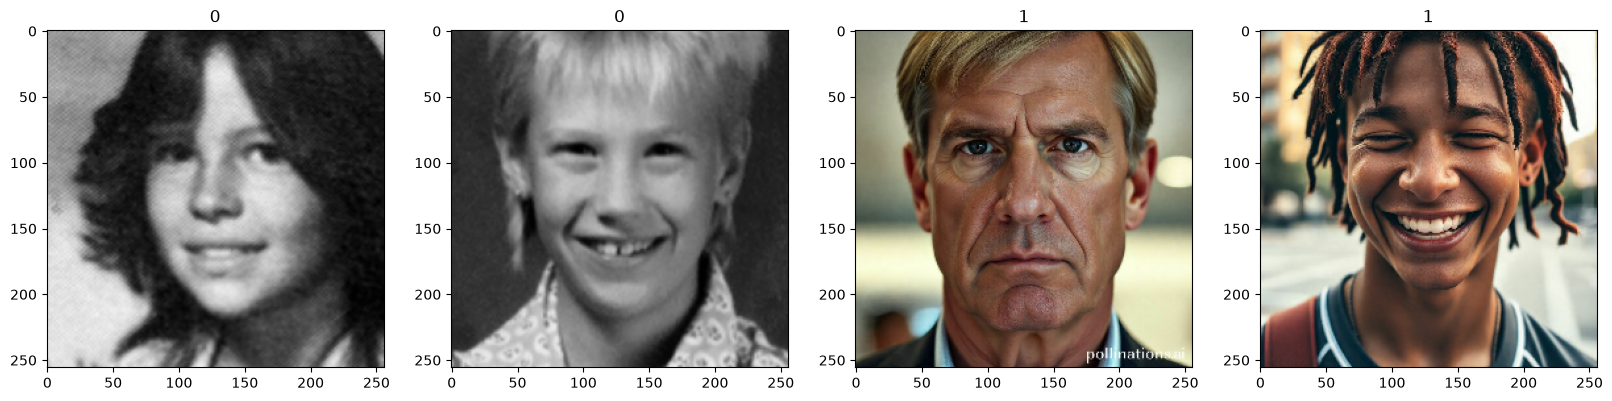

In [ ]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx])

In [ ]:
# SCALE DATA
data = data.map(lambda x,y: (x/255, y))

In [ ]:
scaled_iterator = data.as_numpy_iterator()

In [ ]:
batch = scaled_iterator.next()

In [ ]:
batch

(array([[[[6.1176473e-01, 6.1176473e-01, 6.1176473e-01],
          [6.1176473e-01, 6.1176473e-01, 6.1176473e-01],
          [6.1176473e-01, 6.1176473e-01, 6.1176473e-01],
          ...,
          [6.1864275e-01, 6.1864275e-01, 6.1864275e-01],
          [6.0255820e-01, 6.0255820e-01, 6.0255820e-01],
          [5.9215689e-01, 5.9215689e-01, 5.9215689e-01]],
 
         [[6.0879290e-01, 6.0879290e-01, 6.0879290e-01],
          [6.0822988e-01, 6.0822988e-01, 6.0822988e-01],
          [6.0735923e-01, 6.0735923e-01, 6.0735923e-01],
          ...,
          [6.1895621e-01, 6.1895621e-01, 6.1895621e-01],
          [6.0809553e-01, 6.0809553e-01, 6.0809553e-01],
          [6.0107231e-01, 6.0107231e-01, 6.0107231e-01]],
 
         [[6.0419732e-01, 6.0419732e-01, 6.0419732e-01],
          [6.0276365e-01, 6.0276365e-01, 6.0276365e-01],
          [6.0054660e-01, 6.0054660e-01, 6.0054660e-01],
          ...,
          [6.1944091e-01, 6.1944091e-01, 6.1944091e-01],
          [6.1665839e-01, 6.1665839e-

In [ ]:
batch[0].min()

np.float32(0.0)

In [ ]:
# SPLIT DATA
len(data)

6

In [ ]:
train_size = int(len(data)*.7)+5
val_size = int(len(data) * .2)+5
test_size = int(len(data) * .1)+5

In [ ]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

In [ ]:
# DEEP LEARNING MODEL
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

In [ ]:
model = Sequential()

In [ ]:
model.add(Conv2D(16, (3,3), 1, activation='relu', input_shape=(256,256,3)))
model.add(MaxPooling2D())
model.add(Conv2D(32, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())
model.add(Conv2D(16, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile('adam', loss=tf.losses.BinaryCrossentropy(), metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,686,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,696,625 (14.10 MB)

 Trainable params: 3,696,625 (14.10 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# TRAIN

logdir = 'logs'

In [ ]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [ ]:
hist = model.fit(train, epochs=20, validation_data=val, callbacks=[tensorboard_callback])

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 784ms/step - accuracy: 0.6094 - loss: 1.0416 - val_accuracy: 0.5000 - val_loss: 0.6512
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 507ms/step - accuracy: 0.7656 - loss: 0.5269 - val_accuracy: 0.9688 - val_loss: 0.3328
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 425ms/step - accuracy: 0.9922 - loss: 0.2455 - val_accuracy: 0.9688 - val_loss: 0.1460
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 278ms/step - accuracy: 0.9922 - loss: 0.0762 - val_accuracy: 0.9375 - val_loss: 0.1673
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 176ms/step - accuracy: 0.9844 - loss: 0.0475 - val_accuracy: 1.0000 - val_loss: 0.0038
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 168ms/step - accuracy: 0.9922 - loss: 0.0218 - val_accuracy: 1.0000 - val_loss: 7.4873e-04
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 177ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 3.2576e-04
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - 

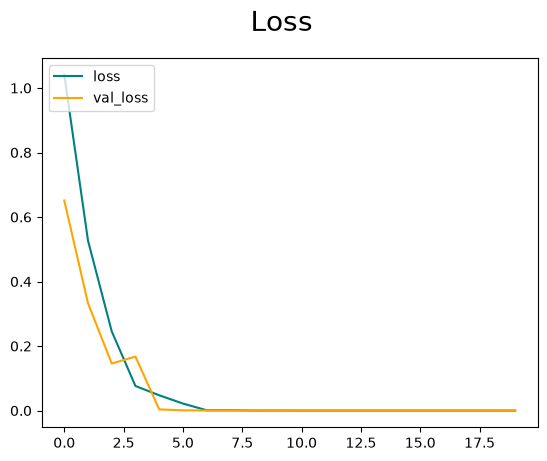

In [ ]:
# PLOT PERFORMANCE
fig = plt.figure()
plt.plot(hist.history['loss'], color='teal', label='loss')
plt.plot(hist.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc="upper left")
plt.show()

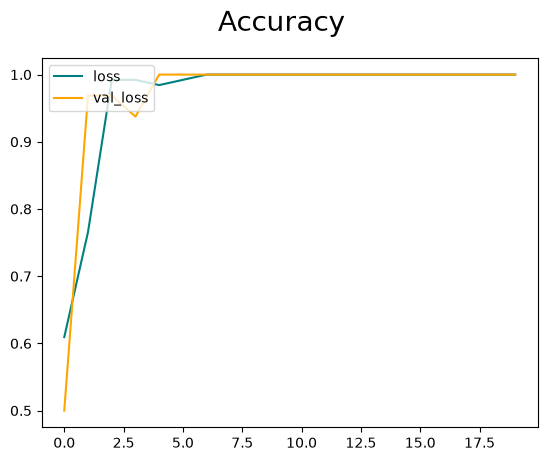

In [ ]:
# ACCURACY
fig = plt.figure()
plt.plot(hist.history['accuracy'], color='teal', label='loss')
plt.plot(hist.history['val_accuracy'], color='orange', label='val_loss')
fig.suptitle('Accuracy', fontsize=20)
plt.legend(loc="upper left")
plt.show()

In [ ]:
from tensorflow.keras.metrics import Precision, Recall, BinaryAccuracy

In [ ]:
pre = Precision()
re = Recall()
acc = BinaryAccuracy()

In [ ]:
for batch in val.as_numpy_iterator():
    X, y = batch
    yhat = model.predict(X)
    pre.update_state(y, yhat)
    re.update_state(y, yhat)
    acc.update_state(y, yhat)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step


In [ ]:
print(f'Precision: {pre.result().numpy()}, Recall: {re.result().numpy()}, Accuracy: {acc.result().numpy()}')

Precision: 1.0, Recall: 1.0, Accuracy: 1.0


In [ ]:
# TEST
import cv2


Found image at: data/AI ai /2_20241130135618_A_close-up_shot_of_a_teenager_female_person_of_Pac.jpg


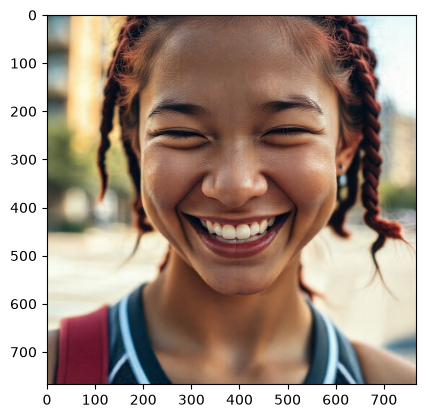

In [ ]:
import glob

# Search for the image inside the data directory recursively
image_name = '2_20241130135618_A_close-up_shot_of_a_teenager_female_person_of_Pac.jpg'
matching_files = glob.glob(f'data/**/{image_name}', recursive=True)

if matching_files:
    img_path = matching_files[0]
    print(f"Found image at: {img_path}")
    # OpenCV reads BGR, so we convert to RGB for Matplotlib
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.show()
else:
    print(f"Could not find '{image_name}' inside the data directory.")

In [ ]:
# Accessing the first prediction from the batch
prediction = yhat[0][0]
if prediction > 0.5:
    print(f'Predicted class is Real ')
else:
    print(f'Predicted class is AI')

Predicted class is AI
